## 18.1 — Environment Setup

We use SHAP to explain the frozen XGBoost model. The fitted
preprocessor and model are loaded from the previous notebook.

This notebook is for post-model diagnostics only. Model 1's
features, hyperparameters, calibration method, and threshold
remain unchanged.

In [1]:
%pip install shap joblib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## 18.2 — Load Frozen Model 1

Load the fitted XGBoost model, fitted preprocessor, isotonic
calibrator, and model configuration saved in Notebook 3.

No model fitting takes place in this step.

In [2]:
import joblib
import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt

final_model = joblib.load("model_1_xgboost.joblib")
final_preprocessor = joblib.load("model_1_preprocessor.joblib")
final_calibrator = joblib.load("model_1_isotonic_calibrator.joblib")
MODEL_1_ARTIFACT_INFO = joblib.load("model_1_artifact_info.joblib")

FINAL_FEATURES = MODEL_1_ARTIFACT_INFO["features"]
FINAL_THRESHOLD = MODEL_1_ARTIFACT_INFO["threshold"]

print("Model artifacts loaded successfully.")
print("Number of input features:", len(FINAL_FEATURES))
print("Calibration:", MODEL_1_ARTIFACT_INFO["calibration"])
print("Operating threshold:", FINAL_THRESHOLD)

Model artifacts loaded successfully.
Number of input features: 20
Calibration: isotonic
Operating threshold: 0.21


## 18.3 — Restore Development Data

Load the saved development features and labels from Notebook 3.

We use development data for SHAP analysis so that the locked
test set remains reserved for final evaluation and subsequent
diagnostics.

The original feature engineering, row selection, and feature
definitions must remain unchanged.

In [3]:
import joblib
import pandas as pd
import numpy as np

X_dev = joblib.load("X_dev.joblib")
y_dev = joblib.load("y_dev.joblib")

print("X_dev shape:", X_dev.shape)
print("y_dev shape:", y_dev.shape)
print("Target distribution:")
print(pd.Series(y_dev).value_counts())

# Verify the original model input features
assert X_dev.columns.tolist() == FINAL_FEATURES, (
    "Feature names or ordering do not match the frozen model."
)

assert len(X_dev) == len(y_dev), "X_dev and y_dev lengths differ."

print("\nDevelopment data loaded and feature order verified.")

X_dev shape: (119999, 20)
y_dev shape: (119999,)
Target distribution:
SeriousDlqin2yrs
0    111978
1      8021
Name: count, dtype: int64

Development data loaded and feature order verified.


### 18.4 — Apply Frozen Preprocessing

Transform `X_dev` using the already-fitted preprocessor. Do not call `fit` or `fit_transform`: doing so could change the representation used by the frozen model.

We also retrieve the transformed feature names so the SHAP plots are interpretable.


In [4]:
# Transform using the fitted preprocessor from Notebook 3
X_dev_transformed = final_preprocessor.transform(X_dev)

# Retrieve names after preprocessing, including one-hot encoded columns
transformed_feature_names = (
    final_preprocessor.get_feature_names_out().tolist()
)

# Create a DataFrame for readable SHAP plots
X_shap_data = pd.DataFrame(
    X_dev_transformed,
    columns=transformed_feature_names,
    index=X_dev.index
)

print("Transformed development shape:", X_shap_data.shape)
print("Number of transformed feature names:", len(transformed_feature_names))

assert X_shap_data.shape[1] == len(transformed_feature_names)

Transformed development shape: (119999, 23)
Number of transformed feature names: 23


### 18.5 — Calculate SHAP Values

Use SHAP's tree explainer to estimate each transformed feature's contribution to the XGBoost model's raw output.

For binary XGBoost, these contributions are generally expressed in raw-margin (log-odds) space, not directly as probability-point changes. We'll interpret them accordingly.


In [5]:
import shap

SHAP_SAMPLE_SIZE = min(2000, len(X_shap_data))

X_shap_sample = X_shap_data.sample(
    n=SHAP_SAMPLE_SIZE,
    random_state=42
)

explainer = shap.TreeExplainer(final_model)

shap_values = explainer.shap_values(X_shap_sample)

print("SHAP calculation complete.")
print("Sample shape:", X_shap_sample.shape)
print("SHAP values shape:", np.asarray(shap_values).shape)

SHAP calculation complete.
Sample shape: (2000, 23)
SHAP values shape: (2000, 23)


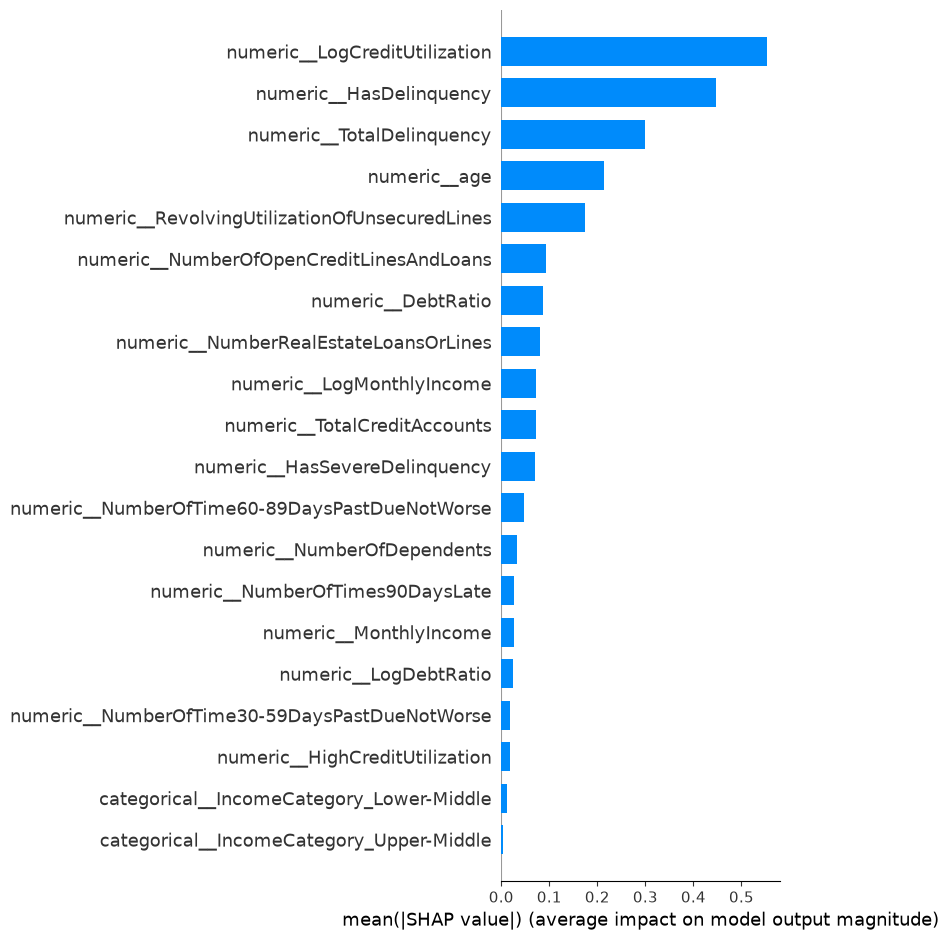

In [6]:
shap.summary_plot(
    shap_values,
    X_shap_sample,
    plot_type="bar",
    max_display=20,
    show=True
)

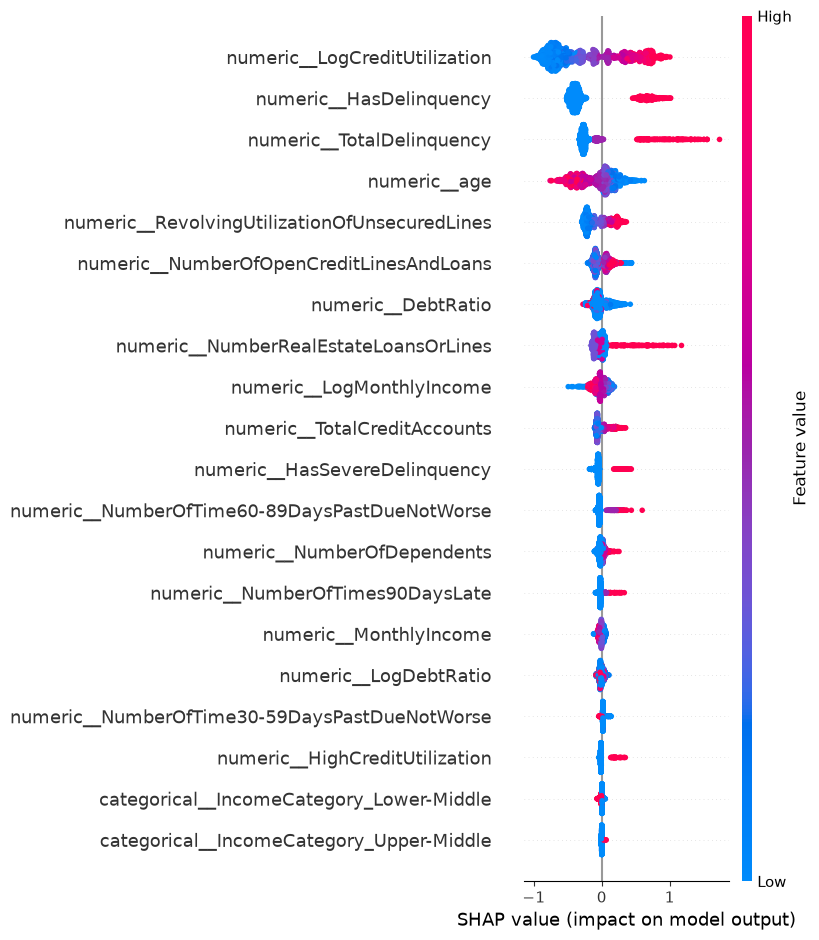

In [7]:
shap.summary_plot(
    shap_values,
    X_shap_sample,
    max_display=20,
    show=True
)

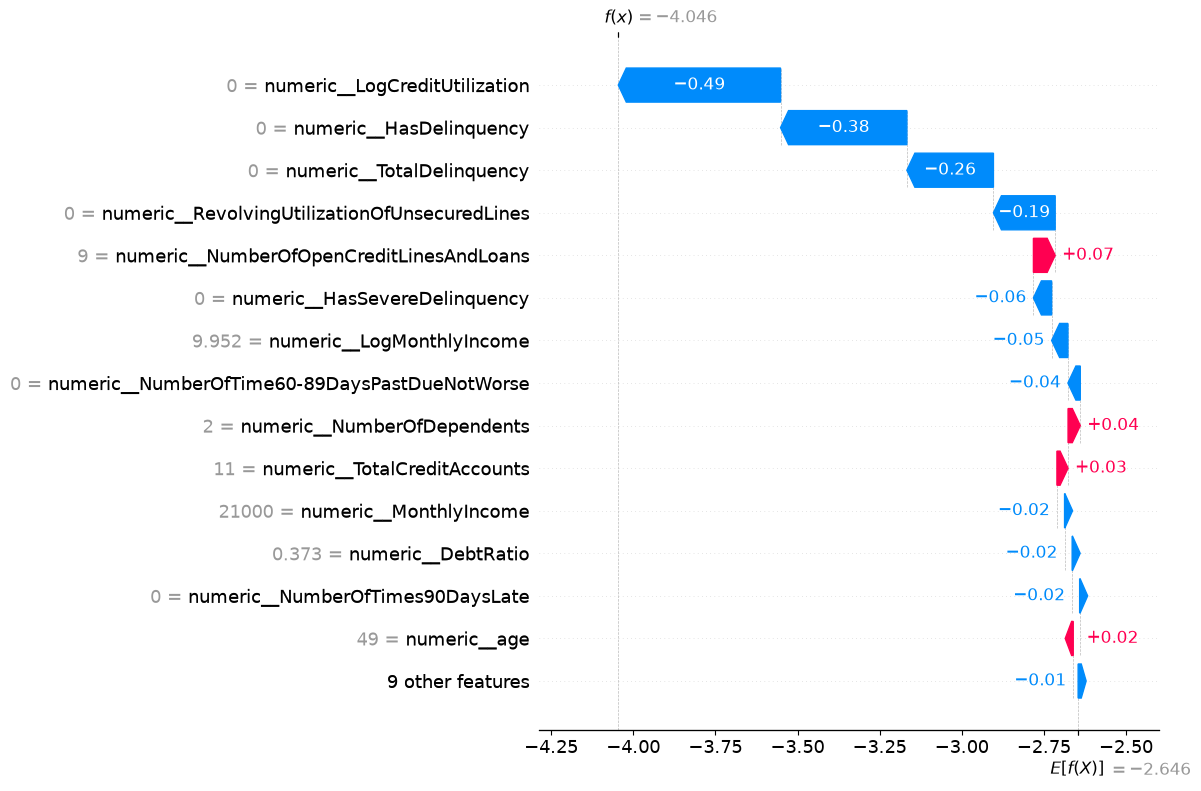

In [8]:
# Explain one borrower from the existing SHAP sample
row_index = 0

waterfall_explanation = shap.Explanation(
    values=np.asarray(shap_values)[row_index],
    base_values=explainer.expected_value,
    data=X_shap_sample.iloc[row_index].values,
    feature_names=X_shap_sample.columns.tolist()
)

shap.plots.waterfall(waterfall_explanation, max_display=15)

In [9]:
# Retrieve the original row corresponding to the selected SHAP observation
selected_index = X_shap_sample.index[0]

selected_raw_probability = final_model.predict_proba(
    final_preprocessor.transform(X_dev.loc[[selected_index]])
)[:, 1][0]

selected_calibrated_probability = final_calibrator.predict(
    np.array([selected_raw_probability])
)[0]

print(f"Raw XGBoost probability: {selected_raw_probability:.4%}")
print(f"Isotonic-calibrated probability: {selected_calibrated_probability:.4%}")
print(f"Operating threshold: {FINAL_THRESHOLD:.2f}")
print(
    "Predicted class:",
    int(selected_calibrated_probability >= FINAL_THRESHOLD)
)

Raw XGBoost probability: 1.7199%
Isotonic-calibrated probability: 1.5621%
Operating threshold: 0.21
Predicted class: 0


### 18.6 — Local SHAP Explanation

A borrower-level SHAP waterfall plot was generated for an observation from the development sample.

The XGBoost model produced a raw probability of **1.7199%**, which the fitted isotonic calibrator mapped to **1.5621%**. Applying the frozen operating threshold of **0.21**, selected by maximizing F1 on calibrated out-of-fold development predictions, resulted in a predicted class of **0**.

The waterfall plot showed that `LogCreditUtilization`, `HasDelinquency`, `TotalDelinquency`, and `RevolvingUtilizationOfUnsecuredLines` made the largest negative contributions to this observation's raw model output. Smaller positive contributions from other features partly offset these effects.

This example demonstrates how SHAP can explain an individual prediction. It is illustrative and does not establish causal relationships, model-wide behavior, or a lending decision.


In [10]:
# Verify SHAP contributions sum to the model's raw output
row_index = 0

shap_sum = (
    float(np.asarray(explainer.expected_value).reshape(-1)[0])
    + np.asarray(shap_values)[row_index].sum()
)

model_raw_output = final_model.predict(
    X_shap_sample.iloc[[row_index]],
    output_margin=True
)[0]

print(f"SHAP reconstructed output: {shap_sum:.6f}")
print(f"XGBoost raw output:        {model_raw_output:.6f}")
print(f"Absolute difference:       {abs(shap_sum - model_raw_output):.8f}")

SHAP reconstructed output: -4.045578
XGBoost raw output:        -4.045574
Absolute difference:       0.00000477


#### SHAP Additivity Validation

The SHAP explanation was validated by comparing the reconstructed model output with XGBoost's raw prediction margin.

* SHAP reconstructed output: **−4.045578**
* XGBoost raw output: **−4.045574**
* Absolute difference: **0.00000477**

The negligible difference confirms that the SHAP contributions reconstruct the model's raw output to within numerical precision for the selected observation.


### 19.1 — Define Age Groups for Fairness Analysis

Age is the only demographic-related variable available in the supplied feature list. We will use age groups to compare model performance and classification outcomes.

These groups are analytical bins for this assessment, not legally defined categories. We will preserve the original age feature and will not retrain or modify the frozen model.


In [11]:
import numpy as np
import pandas as pd

# Use the original development dataset
age_data = X_dev[["age"]].copy()
age_data["y_true"] = np.asarray(y_dev)

age_bins = [0, 30, 40, 50, 60, 70, 120]
age_labels = [
    "30 and below",
    "31-40",
    "41-50",
    "51-60",
    "61-70",
    "71 and above"
]

age_data["age_group"] = pd.cut(
    age_data["age"],
    bins=age_bins,
    labels=age_labels,
    include_lowest=True
)

age_summary = (
    age_data.groupby("age_group", observed=False)
    .agg(
        borrowers=("y_true", "size"),
        actual_defaults=("y_true", "sum"),
        mean_age=("age", "mean")
    )
)

age_summary["actual_default_rate"] = (
    age_summary["actual_defaults"] / age_summary["borrowers"]
)

age_summary.round(4)

,borrowers,actual_defaults,mean_age,actual_default_rate
age_group,,,,
30 and below,8588,971,26.9539,0.1131
31-40,19439,1910,35.9118,0.0983
41-50,27996,2294,45.7319,0.0819
51-60,27907,1742,55.3958,0.0624
61-70,21942,777,64.8485,0.0354
71 and above,14127,327,77.7969,0.0231


In [12]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    confusion_matrix
)

# Obtain calibrated probabilities from the frozen pipeline
X_dev_transformed = final_preprocessor.transform(X_dev)

dev_raw_probability = final_model.predict_proba(
    X_dev_transformed
)[:, 1]

dev_calibrated_probability = final_calibrator.predict(
    dev_raw_probability
)

dev_predictions = (
    dev_calibrated_probability >= FINAL_THRESHOLD
).astype(int)

fairness_data = pd.DataFrame({
    "age": X_dev["age"].to_numpy(),
    "y_true": np.asarray(y_dev),
    "probability": dev_calibrated_probability,
    "y_pred": dev_predictions
})

fairness_data["age_group"] = pd.cut(
    fairness_data["age"],
    bins=age_bins,
    labels=age_labels,
    include_lowest=True
)

rows = []

for group, group_df in fairness_data.groupby(
    "age_group", observed=False
):
    if group_df.empty:
        continue

    y_true_group = group_df["y_true"].to_numpy()
    y_pred_group = group_df["y_pred"].to_numpy()
    y_prob_group = group_df["probability"].to_numpy()

    tn, fp, fn, tp = confusion_matrix(
        y_true_group,
        y_pred_group,
        labels=[0, 1]
    ).ravel()

    positives = tp + fn
    negatives = tn + fp

    rows.append({
        "age_group": str(group),
        "n": len(group_df),
        "actual_default_rate": y_true_group.mean(),
        "predicted_positive_rate": y_pred_group.mean(),
        "precision": precision_score(
            y_true_group, y_pred_group, zero_division=0
        ),
        "recall": recall_score(
            y_true_group, y_pred_group, zero_division=0
        ),
        "false_positive_rate": fp / negatives if negatives else np.nan,
        "false_negative_rate": fn / positives if positives else np.nan,
        "roc_auc": (
            roc_auc_score(y_true_group, y_prob_group)
            if len(np.unique(y_true_group)) == 2
            else np.nan
        ),
        "pr_auc": (
            average_precision_score(y_true_group, y_prob_group)
            if positives > 0
            else np.nan
        ),
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn
    })

age_fairness_results = pd.DataFrame(rows).set_index("age_group")

age_fairness_results.round(4)

,n,actual_default_rate,predicted_positive_rate,precision,recall,false_positive_rate,false_negative_rate,roc_auc,pr_auc,TP,FP,FN,TN
age_group,,,,,,,,,,,,,
30 and below,8588,0.1131,0.1918,0.3613,0.6128,0.1381,0.3872,0.8330,0.4255,595,1052,376,6565
31-40,19439,0.0983,0.1547,0.3846,0.6058,0.1056,0.3942,0.8534,0.4608,1157,1851,753,15678
41-50,27996,0.0819,0.1182,0.3967,0.5724,0.0777,0.4276,0.8617,0.4405,1313,1997,981,23705
51-60,27907,0.0624,0.0857,0.3757,0.5161,0.0571,0.4839,0.8643,0.3887,899,1494,843,24671
61-70,21942,0.0354,0.0415,0.3703,0.4337,0.0271,0.5663,0.8757,0.3516,337,573,440,20592
71 and above,14127,0.0231,0.0207,0.3973,0.3547,0.0128,0.6453,0.8787,0.3224,116,176,211,13624


### 19.3 — Uncertainty in Age-Group Metrics

The previous analysis identified differences in recall and false-positive rate across age groups. We now quantify uncertainty using 95% Wilson confidence intervals for each group's recall and false-positive rate.

These intervals describe sampling uncertainty within the development sample. They do not correct for model-selection effects or establish that any disparity is caused by age.


In [14]:
from statsmodels.stats.proportion import proportion_confint

interval_rows = []

for group, row in age_fairness_results.iterrows():
    tp = int(row["TP"])
    fn = int(row["FN"])
    fp = int(row["FP"])
    tn = int(row["TN"])

    # Recall = TP / (TP + FN)
    recall_low, recall_high = proportion_confint(
        count=tp,
        nobs=tp + fn,
        alpha=0.05,
        method="wilson"
    )

    # False-positive rate = FP / (FP + TN)
    fpr_low, fpr_high = proportion_confint(
        count=fp,
        nobs=fp + tn,
        alpha=0.05,
        method="wilson"
    )

    interval_rows.append({
        "age_group": group,
        "recall": tp / (tp + fn) if tp + fn else np.nan,
        "recall_95CI_low": recall_low,
        "recall_95CI_high": recall_high,
        "FPR": fp / (fp + tn) if fp + tn else np.nan,
        "FPR_95CI_low": fpr_low,
        "FPR_95CI_high": fpr_high
    })

age_fairness_intervals = pd.DataFrame(
    interval_rows
).set_index("age_group")

age_fairness_intervals.round(4)

,recall,recall_95CI_low,recall_95CI_high,FPR,FPR_95CI_low,FPR_95CI_high
age_group,,,,,,
30 and below,0.6128,0.5817,0.6429,0.1381,0.1305,0.1460
31-40,0.6058,0.5837,0.6274,0.1056,0.1011,0.1102
41-50,0.5724,0.5520,0.5925,0.0777,0.0745,0.0810
51-60,0.5161,0.4926,0.5395,0.0571,0.0544,0.0600
61-70,0.4337,0.3993,0.4688,0.0271,0.0250,0.0293
71 and above,0.3547,0.3048,0.4080,0.0128,0.0110,0.0148


#### 19.4 — SHAP-Based Illustrative Reason Codes

We rank transformed features by their positive SHAP contributions for a selected borrower. Features with positive contributions push the XGBoost raw output toward a higher predicted delinquency probability.

The resulting labels are illustrative model explanations, not validated adverse-action reasons. Correlated features may produce overlapping explanations, and the output must not be used as a lending decision without further validation.


In [15]:
# Use the same borrower explained in the earlier waterfall plot
row_index = 0

local_shap = np.asarray(shap_values)[row_index]
local_feature_names = X_shap_sample.columns.tolist()

reason_candidates = pd.DataFrame({
    "feature": local_feature_names,
    "feature_value": X_shap_sample.iloc[row_index].to_numpy(),
    "shap_value": local_shap
})

# Positive SHAP values push the raw model output toward higher risk
top_risk_reasons = (
    reason_candidates[reason_candidates["shap_value"] > 0]
    .sort_values("shap_value", ascending=False)
    .head(5)
    .reset_index(drop=True)
)

top_risk_reasons

,feature,feature_value,shap_value
0,numeric__NumberOfOpenCreditLinesAndLoans,9.0,0.066247
1,numeric__NumberOfDependents,2.0,0.037193
2,numeric__TotalCreditAccounts,11.0,0.033882
3,numeric__age,49.0,0.019516
4,numeric__NumberOfTime30-59DaysPastDueNotWorse,0.0,0.017104


In [16]:
reason_labels = {
    "numeric__LogCreditUtilization":
        "Credit utilization contributed to a higher predicted risk",
    "numeric__RevolvingUtilizationOfUnsecuredLines":
        "Unsecured revolving utilization contributed to a higher predicted risk",
    "numeric__HasDelinquency":
        "Delinquency indicator contributed to a higher predicted risk",
    "numeric__TotalDelinquency":
        "Delinquency history contributed to a higher predicted risk",
    "numeric__HasSevereDelinquency":
        "Severe delinquency indicator contributed to a higher predicted risk",
    "numeric__age":
        "Age contributed to a higher predicted risk",
    "numeric__DebtRatio":
        "Debt ratio contributed to a higher predicted risk",
    "numeric__LogDebtRatio":
        "Transformed debt ratio contributed to a higher predicted risk",
    "numeric__LogMonthlyIncome":
        "Transformed monthly income contributed to a higher predicted risk",
    "numeric__NumberOfDependents":
        "Number of dependents contributed to a higher predicted risk",
    "numeric__NumberOfOpenCreditLinesAndLoans":
        "Number of open credit lines contributed to a higher predicted risk",
    "numeric__NumberRealEstateLoansOrLines":
        "Real-estate loan count contributed to a higher predicted risk",
    "numeric__TotalCreditAccounts":
        "Total credit account count contributed to a higher predicted risk",
}

top_risk_reasons["reason"] = top_risk_reasons["feature"].map(
    reason_labels
).fillna(
    top_risk_reasons["feature"].str.replace(
        "categorical__", "", regex=False
    ) + " contributed to a higher predicted risk"
)

top_risk_reasons[
    ["reason", "feature_value", "shap_value"]
]

,reason,feature_value,shap_value
0,Number of open credit lines contributed to a h...,9.0,0.066247
1,Number of dependents contributed to a higher p...,2.0,0.037193
2,Total credit account count contributed to a hi...,11.0,0.033882
3,Age contributed to a higher predicted risk,49.0,0.019516
4,numeric__NumberOfTime30-59DaysPastDueNotWorse ...,0.0,0.017104


### 20.1 — Performance Across Risk Bands

Group development observations by their frozen model's calibrated probabilities. Compare observed default rates with mean predicted probabilities within each band.

This is a diagnostic check of probability behavior, not a recalibration step. The isotonic calibrator and operating threshold remain frozen.


In [17]:
risk_band_data = pd.DataFrame({
    "y_true": np.asarray(y_dev),
    "calibrated_probability": dev_calibrated_probability
})

risk_band_data["risk_band"] = pd.qcut(
    risk_band_data["calibrated_probability"],
    q=10,
    duplicates="drop"
)

risk_band_summary = (
    risk_band_data.groupby("risk_band", observed=False)
    .agg(
        borrowers=("y_true", "size"),
        actual_default_rate=("y_true", "mean"),
        mean_predicted_probability=(
            "calibrated_probability", "mean"
        )
    )
)

risk_band_summary["absolute_gap"] = (
    risk_band_summary["actual_default_rate"]
    - risk_band_summary["mean_predicted_probability"]
).abs()

risk_band_summary.round(4)

,borrowers,actual_default_rate,mean_predicted_probability,absolute_gap
risk_band,,,,
"(-0.001, 0.00314]",14659,0.0027,0.0031,0.0004
"(0.00314, 0.00667]",10627,0.0045,0.0066,0.0021
"(0.00667, 0.0117]",12923,0.0087,0.0101,0.0014
"(0.0117, 0.0151]",11383,0.0131,0.0133,0.0002
"(0.0151, 0.0201]",11840,0.0174,0.0173,0.0001
"(0.0201, 0.0342]",16160,0.0286,0.0304,0.0018
"(0.0342, 0.0524]",10248,0.0459,0.0481,0.0023
"(0.0524, 0.0933]",8992,0.0694,0.0761,0.0067
"(0.0933, 0.196]",11535,0.1283,0.1265,0.0018


### 20.2 — Bootstrap Uncertainty Analysis

We use bootstrap resampling of the existing development predictions to estimate uncertainty in ROC-AUC, PR-AUC, and Brier score.

The model and predictions remain fixed. This analysis does not retrain the model or select a new threshold. Because the predictions are generated on development data, the resulting intervals should not be interpreted as unbiased confidence intervals for final generalization performance.


In [18]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss
)

y_boot = np.asarray(y_dev)
p_boot = np.asarray(dev_calibrated_probability)

assert len(y_boot) == len(p_boot)

rng = np.random.default_rng(42)
N_BOOTSTRAPS = 500

bootstrap_results = []

for b in range(N_BOOTSTRAPS):
    idx = rng.integers(0, len(y_boot), size=len(y_boot))

    y_sample = y_boot[idx]
    p_sample = p_boot[idx]

    # ROC-AUC and PR-AUC require both target classes
    if np.unique(y_sample).size < 2:
        continue

    bootstrap_results.append({
        "ROC-AUC": roc_auc_score(y_sample, p_sample),
        "PR-AUC": average_precision_score(y_sample, p_sample),
        "Brier": brier_score_loss(y_sample, p_sample)
    })

bootstrap_df = pd.DataFrame(bootstrap_results)

bootstrap_summary = pd.DataFrame({
    "Estimate": {
        "ROC-AUC": roc_auc_score(y_boot, p_boot),
        "PR-AUC": average_precision_score(y_boot, p_boot),
        "Brier": brier_score_loss(y_boot, p_boot)
    },
    "95% CI Lower": bootstrap_df.quantile(0.025),
    "95% CI Upper": bootstrap_df.quantile(0.975)
})

bootstrap_summary.round(4)

,Estimate,95% CI Lower,95% CI Upper
ROC-AUC,0.8735,0.8695,0.8771
PR-AUC,0.4196,0.4088,0.4314
Brier,0.0480,0.0471,0.0488


### 20.3 — Predicted Score Distribution by Age

Summarize the calibrated predicted probabilities across age groups. We report the mean, median, and selected percentiles to understand how risk scores are distributed.

Differences in these distributions are descriptive. They do not independently establish unfairness, and this analysis will not alter the model or threshold.


In [19]:
score_group_data = pd.DataFrame({
    "age": X_dev["age"].to_numpy(),
    "y_true": np.asarray(y_dev),
    "calibrated_probability": dev_calibrated_probability
})

score_group_data["age_group"] = pd.cut(
    score_group_data["age"],
    bins=age_bins,
    labels=age_labels,
    include_lowest=True
)

score_distribution = (
    score_group_data.groupby("age_group", observed=False)
    .agg(
        borrowers=("calibrated_probability", "size"),
        mean_probability=("calibrated_probability", "mean"),
        median_probability=("calibrated_probability", "median"),
        p90=("calibrated_probability", lambda s: s.quantile(0.90)),
        p95=("calibrated_probability", lambda s: s.quantile(0.95)),
        actual_default_rate=("y_true", "mean")
    )
)

score_distribution.round(4)

,borrowers,mean_probability,median_probability,p90,p95,actual_default_rate
age_group,,,,,,
30 and below,8588,0.1134,0.0524,0.3110,0.4147,0.1131
31-40,19439,0.0994,0.0375,0.2762,0.4147,0.0983
41-50,27996,0.0819,0.0342,0.2298,0.3827,0.0819
51-60,27907,0.0624,0.0201,0.1628,0.3110,0.0624
61-70,21942,0.0355,0.0117,0.0732,0.1628,0.0354
71 and above,14127,0.0219,0.0067,0.0358,0.0933,0.0231


### 20.4 — Robustness Assessment Limitations

The robustness checks are diagnostic analyses of the frozen Model 1 pipeline.

* Bootstrap intervals quantify resampling variability in the available predictions; they do not eliminate development-data optimism.
* Age-group comparisons identify observed differences but do not establish their cause.
* Probability distributions can differ because of outcome prevalence, feature distributions, and model behavior.
* No model, calibrator, feature set, hyperparameter, or operating-threshold changes are permitted as a result of these checks.

Any concern identified should be documented as a candidate for a future model iteration, not used to silently modify Model 1.


# Step 21 — Package and document Model 1

Your main modeling workflow is complete: the tuned XGBoost model, preprocessing pipeline, isotonic calibrator, and OOF-selected threshold have been frozen. The fairness and robustness checks are diagnostic only; they should not trigger changes to Model 1.

The next step is to package the artifacts so you can reload the complete pipeline without repeating training. We’ll also save the model’s configuration and final evaluation record for reproducibility.

In [20]:

import os
import joblib
import pandas as pd
import sklearn
import xgboost
import shap

ARTIFACT_DIR = "model_1_artifacts"
os.makedirs(ARTIFACT_DIR, exist_ok=True)

# Package the complete inference pipeline.
MODEL_1_BUNDLE = {
    "model": final_model,
    "preprocessor": final_preprocessor,
    "calibrator": final_calibrator,
    "threshold": float(FINAL_THRESHOLD),
    "metadata": MODEL_1_ARTIFACT_INFO,
}

bundle_path = os.path.join(ARTIFACT_DIR, "model_1_bundle.joblib")
joblib.dump(MODEL_1_BUNDLE, bundle_path)

# Save metadata separately for convenient inspection.
joblib.dump(
    MODEL_1_ARTIFACT_INFO,
    os.path.join(ARTIFACT_DIR, "model_1_metadata.joblib")
)

# Save final test evaluation that was recorded previously.
test_metrics = MODEL_1_ARTIFACT_INFO.get("test_evaluation")

if test_metrics:
    pd.DataFrame([test_metrics]).to_csv(
        os.path.join(ARTIFACT_DIR, "model_1_test_metrics.csv"),
        index=False
    )
else:
    print("No test_evaluation found in metadata; metrics CSV not created.")

# Record the library versions used in this notebook environment.
environment_info = {
    "scikit_learn": sklearn.__version__,
    "xgboost": xgboost.__version__,
    "shap": shap.__version__,
}

pd.DataFrame(
    [environment_info]
).to_csv(
    os.path.join(ARTIFACT_DIR, "environment_versions.csv"),
    index=False
)

print("Model bundle saved:", bundle_path)
print("Threshold:", MODEL_1_BUNDLE["threshold"])
print("Calibration:", MODEL_1_ARTIFACT_INFO.get("calibration"))
print("Artifacts:", os.listdir(ARTIFACT_DIR))

Model bundle saved: model_1_artifacts\model_1_bundle.joblib
Threshold: 0.21
Calibration: isotonic
Artifacts: ['environment_versions.csv', 'model_1_bundle.joblib', 'model_1_metadata.joblib', 'model_1_test_metrics.csv']


In [21]:

loaded_bundle = joblib.load(
    os.path.join(ARTIFACT_DIR, "model_1_bundle.joblib")
)

assert loaded_bundle["model"] is not None
assert loaded_bundle["preprocessor"] is not None
assert loaded_bundle["calibrator"] is not None
assert 0 < loaded_bundle["threshold"] < 1

print("Bundle reload successful.")
print("Model:", type(loaded_bundle["model"]).__name__)
print("Preprocessor:", type(loaded_bundle["preprocessor"]).__name__)
print("Calibrator:", type(loaded_bundle["calibrator"]).__name__)
print("Decision threshold:", loaded_bundle["threshold"])

Bundle reload successful.
Model: XGBClassifier
Preprocessor: ColumnTransformer
Calibrator: IsotonicRegression
Decision threshold: 0.21


# Step 22 — Define a monitoring plan

Saving the model completes the packaging step. The final project step is to document how you would monitor the model if it were deployed. Because you do not have ongoing production data in this project, describe this as a proposed monitoring plan, not a live monitoring system.

In [22]:

monitoring_plan = pd.DataFrame([
    {
        "area": "Input drift",
        "monitor": "Feature distributions and missing-value rates",
        "frequency": "Monthly, or after major data changes",
        "action": "Investigate material changes before considering retraining"
    },
    {
        "area": "Score drift",
        "monitor": "Distribution of calibrated risk scores",
        "frequency": "Monthly",
        "action": "Investigate shifts in score distribution"
    },
    {
        "area": "Predictive performance",
        "monitor": "PR-AUC, ROC-AUC, precision, recall and Brier score",
        "frequency": "When sufficiently mature outcome labels become available",
        "action": "Compare against a documented baseline"
    },
    {
        "area": "Calibration",
        "monitor": "Predicted versus observed default rates",
        "frequency": "When outcome labels become available",
        "action": "Investigate calibration deterioration"
    },
    {
        "area": "Age-group analysis",
        "monitor": "Recall, false-positive rate, precision and group sample sizes",
        "frequency": "Periodic review when labels are available",
        "action": "Investigate disparities and relevant data or policy causes"
    },
    {
        "area": "Operational health",
        "monitor": "Invalid inputs, prediction errors and inference latency",
        "frequency": "Continuous in a deployed service",
        "action": "Investigate failures and data-quality issues"
    }
])

display(monitoring_plan)
monitoring_plan.to_csv(
    os.path.join(ARTIFACT_DIR, "proposed_monitoring_plan.csv"),
    index=False
)

,area,monitor,frequency,action
0,Input drift,Feature distributions and missing-value rates,"Monthly, or after major data changes",Investigate material changes before considerin...
1,Score drift,Distribution of calibrated risk scores,Monthly,Investigate shifts in score distribution
2,Predictive performance,"PR-AUC, ROC-AUC, precision, recall and Brier s...",When sufficiently mature outcome labels become...,Compare against a documented baseline
3,Calibration,Predicted versus observed default rates,When outcome labels become available,Investigate calibration deterioration
4,Age-group analysis,"Recall, false-positive rate, precision and gro...",Periodic review when labels are available,Investigate disparities and relevant data or p...
5,Operational health,"Invalid inputs, prediction errors and inferenc...",Continuous in a deployed service,Investigate failures and data-quality issues


# Step 23 — Final project audit

In [25]:

import os
import joblib
import pandas as pd

bundle_path = os.path.join(
    "model_1_artifacts",
    "model_1_bundle.joblib"
)

assert os.path.exists(bundle_path), "Model bundle is missing."

bundle = joblib.load(bundle_path)

required_components = [
    "model",
    "preprocessor",
    "calibrator",
    "threshold",
    "metadata",
]

for component in required_components:
    assert component in bundle, f"Missing component: {component}"

assert bundle["threshold"] == 0.21

audit = pd.DataFrame([
    {"Check": "Model bundle exists", "Status": "PASS"},
    {"Check": "Model loaded successfully", "Status": "PASS"},
    {"Check": "Preprocessor included", "Status": "PASS"},
    {"Check": "Isotonic calibrator included", "Status": "PASS"},
    {"Check": "Frozen threshold is 0.21", "Status": "PASS"},
    {"Check": "Metadata included", "Status": "PASS"},
])

display(audit)

print("\nModel 1 configuration")
print("Model:", bundle["metadata"].get("model_name"))
print("Calibration:", bundle["metadata"].get("calibration"))
print("Threshold:", bundle["threshold"])
print("Primary metric:", bundle["metadata"].get("primary_metric"))

,Check,Status
0,Model bundle exists,PASS
1,Model loaded successfully,PASS
2,Preprocessor included,PASS
3,Isotonic calibrator included,PASS
4,Frozen threshold is 0.21,PASS
5,Metadata included,PASS



Model 1 configuration
Model: Frozen XGBoost Model 1
Calibration: isotonic
Threshold: 0.21
Primary metric: PR-AUC


In [24]:
print(MODEL_1_ARTIFACT_INFO.keys())
print(MODEL_1_ARTIFACT_INFO)

dict_keys(['model_name', 'feature_set', 'features', 'class_weighting', 'monotonic_constraints', 'xgb_params', 'calibration', 'threshold', 'threshold_selection', 'primary_metric', 'cv', 'test_evaluation'])
{'model_name': 'Frozen XGBoost Model 1', 'feature_set': 'full', 'features': ['RevolvingUtilizationOfUnsecuredLines', 'age', 'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'MonthlyIncome', 'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate', 'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse', 'NumberOfDependents', 'TotalDelinquency', 'HasDelinquency', 'HasSevereDelinquency', 'LogCreditUtilization', 'HighCreditUtilization', 'LogMonthlyIncome', 'IncomeCategory', 'LogDebtRatio', 'HighDebtRatio', 'TotalCreditAccounts'], 'class_weighting': False, 'monotonic_constraints': False, 'xgb_params': {'subsample': 1.0, 'reg_lambda': 2, 'reg_alpha': 0.5, 'n_estimators': 500, 'min_child_weight': 10, 'max_depth': 4, 'learning_rate': 0.02, 'gamma': 0, 'colsample_bytree

In [26]:
import pandas as pd

test_metrics = bundle["metadata"].get("test_evaluation")

if test_metrics:
    display(pd.DataFrame([test_metrics]).T.rename(
        columns={0: "Final Test Result"}
    ))
else:
    print("Final test metrics were not found in the saved metadata.")
    print("Check the final evaluation output from Notebook 3.")

,Final Test Result
ROC-AUC,0.869620
PR-AUC,0.391852
KS,0.588293
Brier,0.048958
Accuracy,0.910367
Precision,0.380084
Recall,0.540648
F1,0.446366
TN,26227.000000
FP,1768.000000
